In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline


In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:

df = pd.read_csv('/content/drive/MyDrive/sentiment.csv')

In [4]:
# text processing libraries

from wordcloud import WordCloud
import nltk
import re #regular repression for text cleaning
import string #string operation



In [5]:
#download necessary NLTK datasets
nltk.download('punkt') #Tokenizers
nltk.download('stopwords') #stopwords  the ,in,of
nltk.download('wordnet') #WordNet for lemmatization going = go

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [6]:
# importing additional NLTK components

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [7]:
#  INitializing stopwords
stop_words = stopwords.words('english') #english stopwords for english language

In [8]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [9]:
df.info(
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [10]:
df.describe().T

,count,unique,top,freq
review,50000,49582,Loved today's show!!! It was a variety and not...,5
sentiment,50000,2,positive,25000


In [11]:
# sentiment count
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

<Axes: >

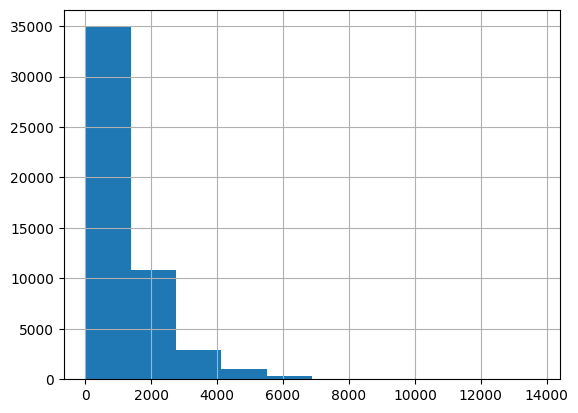

In [12]:
df['review'].str.len().hist()

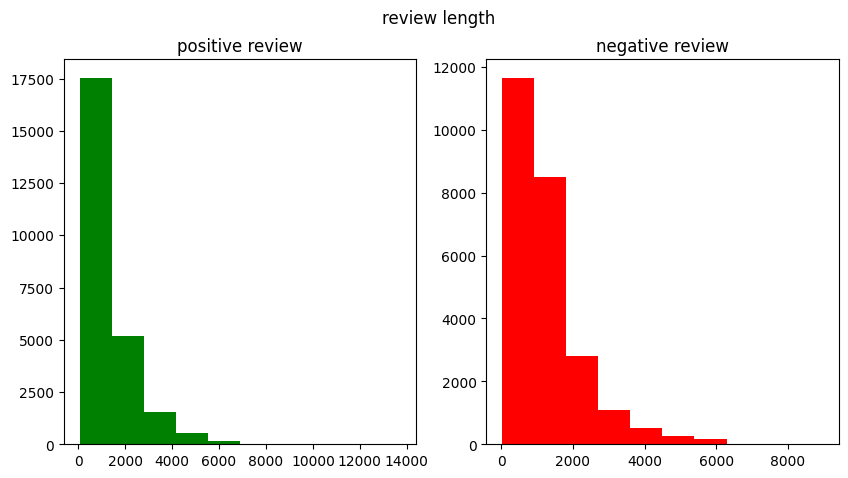

In [13]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,5))
ax1.hist(df[df['sentiment']=='positive']['review'].str.len(),color='green')
ax1.set_title('positive review')
ax2.hist(df[df['sentiment']=='negative']['review'].str.len(),color='red')
ax2.set_title('negative review')
fig.suptitle('review length')
plt.show()

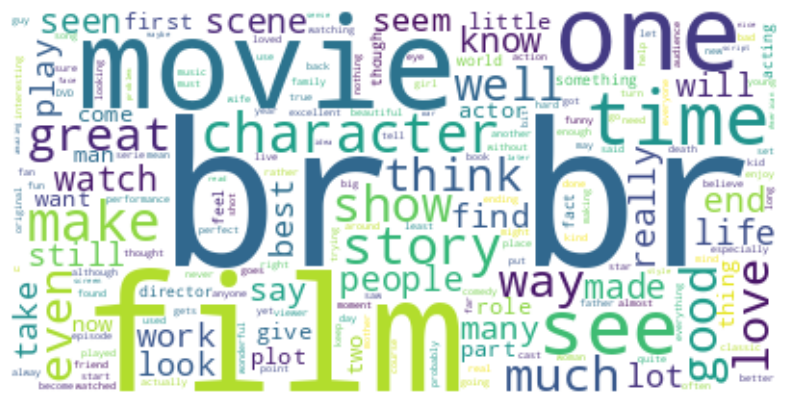

In [14]:
text = " ".join(i for i in df[df['sentiment'] == 'positive']['review'])
wordcloud = WordCloud(background_color="white").generate(text)
plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

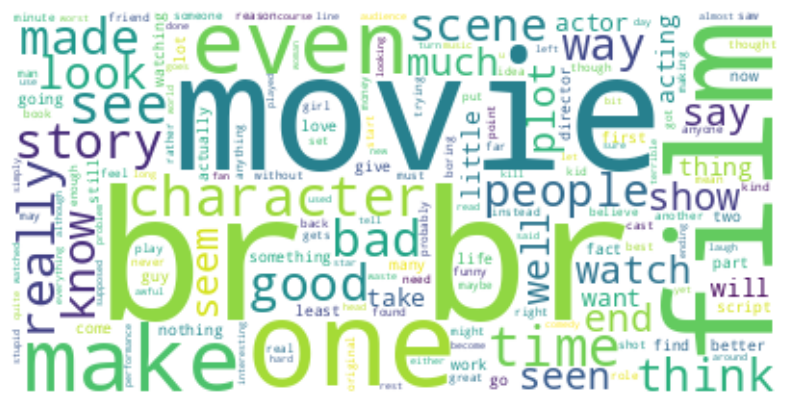

In [15]:
text = " ".join(i for i in df[df['sentiment'] == 'negative']['review'])
wordcloud = WordCloud(background_color="white").generate(text)
plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

In [16]:
df.rename(columns={'review':'text'}, inplace= True)

In [17]:
df


,text,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [18]:
def cleaning(text):
  # converting to lowercase, removing url links,special characters , punctuations
    text = text.lower() # converting to lowercase
    text = re.sub('https?://\S+|www\.\S+', '', text) # removing URL links
    text = re.sub(r"\b\d+\b", "", text) # removing number
    text = re.sub('<.*?>+', '', text) # removing special characters,
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text) # punctuations
    text = re.sub('\n', '', text)
    text = re.sub('[’“”…]', '', text) #removes special charaters like curly quotes

    #removing emoji:
    emoji_pattern = re.compile("["
                           u"\U0001F600-\U0001F64F"  # emoticons
                           u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                           u"\U0001F680-\U0001F6FF"  # transport & map symbols
                           u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                           u"\U00002702-\U000027B0"
                           u"\U000024C2-\U0001F251"
                           "]+", flags=re.UNICODE)
    text = emoji_pattern.sub(r'', text)

   # removing short form:

    text=re.sub("isn't",'is not',text)
    text=re.sub("he's",'he is',text)
    text=re.sub("wasn't",'was not',text)
    text=re.sub("there's",'there is',text)
    text=re.sub("couldn't",'could not',text)
    text=re.sub("won't",'will not',text)
    text=re.sub("they're",'they are',text)
    text=re.sub("she's",'she is',text)
    text=re.sub("There's",'there is',text)
    text=re.sub("wouldn't",'would not',text)
    text=re.sub("haven't",'have not',text)
    text=re.sub("That's",'That is',text)
    text=re.sub("you've",'you have',text)
    text=re.sub("He's",'He is',text)
    text=re.sub("what's",'what is',text)
    text=re.sub("weren't",'were not',text)
    text=re.sub("we're",'we are',text)
    text=re.sub("hasn't",'has not',text)
    text=re.sub("you'd",'you would',text)
    text=re.sub("shouldn't",'should not',text)
    text=re.sub("let's",'let us',text)
    text=re.sub("they've",'they have',text)
    text=re.sub("You'll",'You will',text)
    text=re.sub("i'm",'i am',text)
    text=re.sub("we've",'we have',text)
    text=re.sub("it's",'it is',text)
    text=re.sub("don't",'do not',text)
    text=re.sub("that´s",'that is',text)
    text=re.sub("I´m",'I am',text)
    text=re.sub("it’s",'it is',text)
    text=re.sub("she´s",'she is',text)
    text=re.sub("he’s'",'he is',text)
    text=re.sub('I’m','I am',text)
    text=re.sub('I’d','I did',text)
    text=re.sub("he’s'",'he is',text)
    text=re.sub('there’s','there is',text)


    return text

dt = df['text'].apply(cleaning)

In [19]:
dt

0        one of the other reviewers has mentioned that ...
1        a wonderful little production the filming tech...
2        i thought this was a wonderful way to spend ti...
3        basically theres a family where a little boy j...
4        petter matteis love in the time of money is a ...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot bad dialogue bad acting idiotic direc...
49997    i am a catholic taught in parochial elementary...
49998    im going to have to disagree with the previous...
49999    no one expects the star trek movies to be high...
Name: text, Length: 50000, dtype: object

In [20]:
dt = pd.DataFrame(dt)
dt['sentiment']=df['sentiment']
dt

,text,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tech...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically theres a family where a little boy j...,negative
4,petter matteis love in the time of money is a ...,positive
...,...,...
49995,i thought this movie did a down right good job...,positive
49996,bad plot bad dialogue bad acting idiotic direc...,negative
49997,i am a catholic taught in parochial elementary...,negative
49998,im going to have to disagree with the previous...,negative


In [21]:
# remove stop_words

def remove_stop_words(text):
    # split the text into words
    word = text.split()

    # filter out stop words
    filtered_word = [word for word in word if word not in stop_words]

    # join the words back into a string
    cleaned_text = " ".join(filtered_word)

    return cleaned_text

dt['no_sw'] = dt['text'].apply(remove_stop_words)

In [22]:
dt

,text,sentiment,no_sw
0,one of the other reviewers has mentioned that ...,positive,one reviewers mentioned watching oz episode yo...
1,a wonderful little production the filming tech...,positive,wonderful little production filming technique ...
2,i thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...
3,basically theres a family where a little boy j...,negative,basically theres family little boy jake thinks...
4,petter matteis love in the time of money is a ...,positive,petter matteis love time money visually stunni...
...,...,...,...
49995,i thought this movie did a down right good job...,positive,thought movie right good job wasnt creative or...
49996,bad plot bad dialogue bad acting idiotic direc...,negative,bad plot bad dialogue bad acting idiotic direc...
49997,i am a catholic taught in parochial elementary...,negative,catholic taught parochial elementary schools n...
49998,im going to have to disagree with the previous...,negative,im going disagree previous comment side maltin...


In [23]:
# working with the most frequent words

from collections import Counter
cnt = Counter()
for text in dt['no_sw'].values:
    for word in text.split():
        cnt[word] += 1

cnt.most_common(10)
temp = pd.DataFrame(cnt.most_common(10))
temp.columns = ['words','count']
temp

,words,count
0,movie,83576
1,film,74511
2,one,50392
3,like,38833
4,good,28502
5,even,24283
6,would,24001
7,time,23298
8,really,22900
9,see,22437


In [24]:
px.bar(temp, x ="count", y = "words", title = 'Common Words in Text', orientation='h', width=700, height=700)

In [25]:
# remove the most frequent words

FREQWORDS = set([w for (w, wc) in cnt.most_common(10)])
def remove_freqwords(text):
    """custom function to remove the frequent words"""
    return " ".join([word for word in str(text).split() if word not in FREQWORDS])

def apply_remove_freqwords(column):
  return column.apply(remove_freqwords)

dt["no_stopfreq"] =  apply_remove_freqwords(dt["no_sw"])
dt.head()

,text,sentiment,no_sw,no_stopfreq
0,one of the other reviewers has mentioned that ...,positive,one reviewers mentioned watching oz episode yo...,reviewers mentioned watching oz episode youll ...
1,a wonderful little production the filming tech...,positive,wonderful little production filming technique ...,wonderful little production filming technique ...
2,i thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...,thought wonderful way spend hot summer weekend...
3,basically theres a family where a little boy j...,negative,basically theres family little boy jake thinks...,basically theres family little boy jake thinks...
4,petter matteis love in the time of money is a ...,positive,petter matteis love time money visually stunni...,petter matteis love money visually stunning wa...


In [26]:
dt['no_sw'].loc[5]

'probably alltime favorite movie story selflessness sacrifice dedication noble cause preachy boring never gets old despite seen times last years paul lukas performance brings tears eyes bette davis one truly sympathetic roles delight kids grandma says like dressedup midgets children makes fun watch mothers slow awakening whats happening world roof believable startling dozen thumbs theyd movie'

In [27]:

wordnet_lem = WordNetLemmatizer()

dt['no_stopfreq_lem'] = dt['no_stopfreq'].apply(wordnet_lem.lemmatize)
dt

,text,sentiment,no_sw,no_stopfreq,no_stopfreq_lem
0,one of the other reviewers has mentioned that ...,positive,one reviewers mentioned watching oz episode yo...,reviewers mentioned watching oz episode youll ...,reviewers mentioned watching oz episode youll ...
1,a wonderful little production the filming tech...,positive,wonderful little production filming technique ...,wonderful little production filming technique ...,wonderful little production filming technique ...
2,i thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...,thought wonderful way spend hot summer weekend...,thought wonderful way spend hot summer weekend...
3,basically theres a family where a little boy j...,negative,basically theres family little boy jake thinks...,basically theres family little boy jake thinks...,basically theres family little boy jake thinks...
4,petter matteis love in the time of money is a ...,positive,petter matteis love time money visually stunni...,petter matteis love money visually stunning wa...,petter matteis love money visually stunning wa...
...,...,...,...,...,...
49995,i thought this movie did a down right good job...,positive,thought movie right good job wasnt creative or...,thought right job wasnt creative original firs...,thought right job wasnt creative original firs...
49996,bad plot bad dialogue bad acting idiotic direc...,negative,bad plot bad dialogue bad acting idiotic direc...,bad plot bad dialogue bad acting idiotic direc...,bad plot bad dialogue bad acting idiotic direc...
49997,i am a catholic taught in parochial elementary...,negative,catholic taught parochial elementary schools n...,catholic taught parochial elementary schools n...,catholic taught parochial elementary schools n...
49998,im going to have to disagree with the previous...,negative,im going disagree previous comment side maltin...,im going disagree previous comment side maltin...,im going disagree previous comment side maltin...


In [28]:
# create the clesned data for the train-test data

nb = dt.drop(columns = ['text', 'no_sw', 'no_stopfreq'])
nb.columns=['sentiment', 'review']
nb.sentiment = [0 if each =="negative" else 1 for each in nb.sentiment]
nb



,sentiment,review
0,1,reviewers mentioned watching oz episode youll ...
1,1,wonderful little production filming technique ...
2,1,thought wonderful way spend hot summer weekend...
3,0,basically theres family little boy jake thinks...
4,1,petter matteis love money visually stunning wa...
...,...,...
49995,1,thought right job wasnt creative original firs...
49996,0,bad plot bad dialogue bad acting idiotic direc...
49997,0,catholic taught parochial elementary schools n...
49998,0,im going disagree previous comment side maltin...


In [29]:
tokenized_review = nb['review'].apply(lambda x: x.split())
tokenized_review.head()


0    [reviewers, mentioned, watching, oz, episode, ...
1    [wonderful, little, production, filming, techn...
2    [thought, wonderful, way, spend, hot, summer, ...
3    [basically, theres, family, little, boy, jake,...
4    [petter, matteis, love, money, visually, stunn...
Name: review, dtype: object

In [30]:
from sklearn.feature_extraction.text import CountVectorizer
from nltk.tokenize import RegexpTokenizer
token = RegexpTokenizer(r'[a-zA-Z0-9]+')
cv = CountVectorizer(stop_words='english',ngram_range=(1,1),tokenizer=token.tokenize)
text_counts = cv.fit_transform(nb['review'])

In [31]:
text_counts

<50000x214662 sparse matrix of type '<class 'numpy.int64'>'
	with 4247170 stored elements in Compressed Sparse Row format>

In [32]:
from sklearn.model_selection import train_test_split
x = text_counts
y = nb['sentiment']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)